# Week 3: Principal Component Regression, Partial Least Squares and Feature Selection
Eric Benaroch, Module C Capstone

Research question from my proposal: does malicious behavior leave the same statistical pattern in different threat domains, or is every domain different?

Same datasets and targets as Weeks 1 and 2: CICAndMal2017, CICIDS2017 and WELFake, with log of Flow Bytes/s (network) and log of word count (WELFake) as targets.

Week 2 used penalties to deal with many collinear columns. This week reduces the number of columns instead:
1. Work through the lesson's 2 by 2 PCA example to check the method.
2. Run PCA on the Week 2 feature set and see how many components carry the variance.
3. Check the lesson's claim that PCR with all components is the same as OLS.
4. Pick the number of components for PCR and PLSR with cross-validation.
5. Look for low variance components that still matter for prediction, and show why standardizing matters.
6. Forward and backward selection, including their limits and why their p-values cannot be trusted.
7. Compare the most important directions across domains.

## 1. Setup

In [63]:
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from sklearn.decomposition import PCA
from sklearn.cross_decomposition import PLSRegression
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import r2_score

import os
from pathlib import Path
DATA_DIR = Path(os.environ.get("CAPSTONE_DATA_DIR", "."))   # folder with the zips and the WELFake csv
FIG_DIR = Path("figures_week3"); FIG_DIR.mkdir(exist_ok=True)
SEED = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:.3f}".format)

## 2. The lesson's example
X = [[2, 1], [1, 2]]. Center it, take the eigenvectors of the covariance matrix, and compute the score of each sample. The lesson gets eigenvalues 1 and 0, a first component of [0.707, -0.707], and scores of [0.707, 0] and [-0.707, 0]. sklearn's PCA should give the same thing (it may flip the sign, which does not matter).

Note: the lesson says n is the number of columns, but in 1 / (n - 1) it should be the number of samples (rows). In this example both are 2.

In [65]:
X = np.array([[2, 1], [1, 2]])
X_star = X - X.mean(axis=0)
cov = X_star.T @ X_star / (len(X) - 1)
eigenvalues, eigenvectors = np.linalg.eigh(cov)
print("centered X:\n", X_star)
print("covariance:\n", cov)
print("eigenvalues:", eigenvalues.round(3))
print("eigenvectors (columns):\n", eigenvectors.round(3))

first_pc = eigenvectors[:, np.argmax(eigenvalues)]
print("first principal component:", first_pc.round(3))
print("scores:\n", (X_star @ eigenvectors[:, ::-1]).round(3))

pca = PCA().fit(X)
print("sklearn components:\n", pca.components_.round(3))
print("sklearn scores:\n", pca.transform(X).round(3))

centered X:
 [[ 0.5 -0.5]
 [-0.5  0.5]]
covariance:
 [[ 0.5 -0.5]
 [-0.5  0.5]]
eigenvalues: [0. 1.]
eigenvectors (columns):
 [[-0.707 -0.707]
 [-0.707  0.707]]
first principal component: [-0.707  0.707]
scores:
 [[-0.707  0.   ]
 [ 0.707  0.   ]]
sklearn components:
 [[ 0.707 -0.707]
 [ 0.707  0.707]]
sklearn scores:
 [[ 0.707  0.   ]
 [-0.707  0.   ]]


## 3. Load the data
The CIC files are read straight from the zip files, keeping only the columns used here. For CICAndMal2017 the folder name gives the category (Adware, Benign, Ransomware, Scareware, SMSmalware). For CICIDS2017 I use MachineLearningCSV, which has the same flows as GeneratedLabelledFlows but without IP addresses and timestamps.

In [67]:
COLS = {"Flow Duration": "dur", "Total Fwd Packets": "fwd_pkts", "Total Backward Packets": "bwd_pkts",
        "Fwd Packet Length Mean": "fwd_len", "Bwd Packet Length Mean": "bwd_len",
        "Flow IAT Mean": "iat", "Flow Bytes/s": "bytes_s", "Label": "label"}

def read_zip(zip_name):
    frames = []
    with zipfile.ZipFile(DATA_DIR / zip_name) as z:
        for name in z.namelist():
            if name.endswith(".csv"):
                df = pd.read_csv(z.open(name), skipinitialspace=True, encoding="latin1",
                                 usecols=lambda c: c.strip() in COLS)
                df.columns = df.columns.str.strip()
                frames.append(df)
    return pd.concat(frames, ignore_index=True).rename(columns=COLS)

mal_parts = []
for cat in ["Benign", "Adware", "Ransomware", "Scareware", "SMSmalware"]:
    df = read_zip(f"{cat}-CSVs.zip")
    df["category"] = cat
    mal_parts.append(df)
    print(cat, len(df))
mal_raw = pd.concat(mal_parts, ignore_index=True)

ids_raw = read_zip("MachineLearningCSV.zip")
print("CICIDS2017", len(ids_raw))
print(ids_raw["label"].value_counts())

Benign 1205515
Adware 424147
Ransomware 348943
Scareware 400841
SMSmalware 237133
CICIDS2017 2830743
label
BENIGN                          2273097
DoS Hulk                         231073
PortScan                         158930
DDoS                             128027
DoS GoldenEye                     10293
FTP-Patator                        7938
SSH-Patator                        5897
DoS slowloris                      5796
DoS Slowhttptest                   5499
Bot                                1966
Web Attack ï¿½ Brute Force         1507
Web Attack ï¿½ XSS                  652
Infiltration                         36
Web Attack ï¿½ Sql Injection         21
Heartbleed                           11
Name: count, dtype: int64


Ransomware 348943


Scareware 400841


SMSmalware 237133


CICIDS2017 2830743
label
BENIGN                          2273097
DoS Hulk                         231073
PortScan                         158930
DDoS                             128027
DoS GoldenEye                     10293
FTP-Patator                        7938
SSH-Patator                        5897
DoS slowloris                      5796
DoS Slowhttptest                   5499
Bot                                1966
Web Attack ï¿½ Brute Force         1507
Web Attack ï¿½ XSS                  652
Infiltration                         36
Web Attack ï¿½ Sql Injection         21
Heartbleed                           11
Name: count, dtype: int64


In [68]:
wel_raw = pd.read_csv(next(DATA_DIR.glob("WELFake*.csv")))      # finds WELFake_Dataset.csv
print(wel_raw.shape)
print(wel_raw["label"].value_counts())

# Which label is fake? Real news in WELFake is mostly Reuters wire copy.
print(wel_raw.groupby("label")["text"].apply(lambda s: s.str.contains("(Reuters)", regex=False).mean()))

(72134, 4)
label
1    37106
0    35028
Name: count, dtype: int64
label
0   0.607
1   0.000
Name: text, dtype: float64


The dataset card says label 1 means real, but in this file label 0 has the Reuters articles (about 61%) and label 1 has almost none. So label 1 is treated as fake (malicious = 1).

## 4. Clean and prepare
Network data: remove infinite and missing values, negative values, zero-length flows and duplicates, as in Module B. All flow features are very skewed (a few huge flows), so I take log1p of every feature and the target. I take a random sample so the models run quickly: 60,000 flows per CICAndMal2017 category, and 150,000 benign plus 150,000 attack flows for CICIDS2017.

WELFake: drop empty articles and duplicates, then make simple numeric features from the title and text.

In [71]:
def clean_flows(df):
    num = list(COLS.values())[:-1]
    df = df.copy()
    df[num] = df[num].apply(pd.to_numeric, errors="coerce")
    df = df.replace([np.inf, -np.inf], np.nan).dropna()
    df = df[(df[num] >= 0).all(axis=1) & (df["dur"] > 0)].drop_duplicates()
    for c in num:
        df[c] = np.log1p(df[c])
    return df.rename(columns={"bytes_s": "y"})

mal = clean_flows(mal_raw)
mal["malicious"] = (mal["category"] != "Benign").astype(int)
mal = mal.groupby("category").sample(60000, random_state=SEED)

def attack_group(label):
    label = label.upper()
    if label == "BENIGN": return "Benign"
    if "DOS" in label: return "DoS/DDoS"
    if "PATATOR" in label: return "BruteForce"
    if "WEB ATTACK" in label: return "WebAttack"
    if "PORTSCAN" in label: return "PortScan"
    return "Other"

ids = clean_flows(ids_raw)
ids["category"] = ids["label"].map(attack_group)
ids["malicious"] = (ids["category"] != "Benign").astype(int)
ids = ids.groupby("malicious").sample(150000, random_state=SEED)

print(mal["category"].value_counts(), "\n")
print(ids["category"].value_counts())

category
Adware        60000
Benign        60000
Ransomware    60000
SMSmalware    60000
Scareware     60000
Name: count, dtype: int64 

category
Benign        150000
DoS/DDoS      144190
BruteForce      3453
WebAttack        979
PortScan         762
Other            616
Name: count, dtype: int64


In [72]:
wel = wel_raw.dropna(subset=["text"]).fillna({"title": ""}).drop_duplicates(subset=["title", "text"])
wel = wel[wel["text"].str.split().str.len() > 0].copy()
wel["malicious"] = wel["label"]                                   # 1 = fake
wel["y"] = np.log1p(wel["text"].str.split().str.len())            # target: log word count
wel["title_words"] = np.log1p(wel["title"].str.split().str.len())
wel["title_chars"] = np.log1p(wel["title"].str.len())
wel["title_caps"] = wel["title"].str.count(r"[A-Z]") / wel["title"].str.len().clip(lower=1)   # share of capital letters
wel["exclaim"] = np.log1p(wel["title"].str.count("!") + wel["text"].str.count("!"))
wel["avg_word_len"] = wel["text"].str.len() / wel["text"].str.split().str.len()
wel["avg_word_len"] = wel["avg_word_len"].clip(upper=wel["avg_word_len"].quantile(0.99))
print(len(wel), "articles, fake share =", round(wel["malicious"].mean(), 2))

63110 articles, fake share = 0.45


In [73]:
NET_FEATS = ["dur", "fwd_pkts", "bwd_pkts", "fwd_len", "bwd_len", "iat"]
WEL_FEATS = ["title_words", "title_chars", "title_caps", "exclaim", "avg_word_len"]
DATA = {"CICAndMal2017": (mal, NET_FEATS), "CICIDS2017": (ids, NET_FEATS), "WELFake": (wel, WEL_FEATS)}

## 5. Feature set
The same columns as Week 2: the original features (including the collinear ones), their squares and cubes, the malicious label, and each feature times malicious. Everything is standardized on the training set. As the lesson says, standardizing matters for PCA, because otherwise the feature with the biggest units would dominate.

In [75]:
def add_powers(df_X, degree):
    cols = list(df_X.columns)
    parts = [df_X]
    for d in range(2, degree + 1):
        parts.append((df_X ** d).rename(columns={f"{var}": f"{var}{d}" for var in cols}))
    return pd.concat(parts, axis=1)

def build_X(df, feats, means):
    X = add_powers(df[feats] - means, 3)
    X["malicious"] = df["malicious"]
    for f in feats:
        X[f + "_x_mal"] = (df[f] - means[f]) * df["malicious"]
    return X

SETS, RAW = {}, {}
for name, (df, feats) in DATA.items():
    train, test = train_test_split(df, test_size=0.2, random_state=SEED, stratify=df["malicious"])
    RAW[name] = (train, test)
    means = train[feats].mean()
    X_train, X_test = build_X(train, feats, means), build_X(test, feats, means)
    scaler = StandardScaler().fit(X_train)
    X_train = pd.DataFrame(scaler.transform(X_train), columns=X_train.columns)
    X_test = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns)
    SETS[name] = (X_train, X_test, train["y"].values, test["y"].values)
    print(f"{name}: {X_train.shape[1]} columns, {len(X_train)} train rows")

CICAndMal2017: 25 columns, 240000 train rows
CICIDS2017: 25 columns, 240000 train rows
WELFake: 21 columns, 50488 train rows


## 6. PCA: how much variance each component carries

CICAndMal2017: components needed for 90% of variance = 7, for 99% = 15 (out of 25)
CICIDS2017: components needed for 90% of variance = 8, for 99% = 16 (out of 25)
WELFake: components needed for 90% of variance = 7, for 99% = 13 (out of 21)


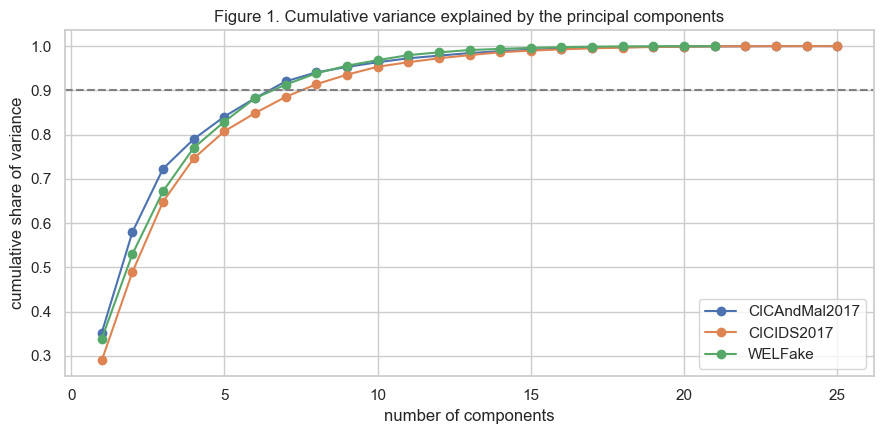

In [77]:
PCAS = {}
fig, ax = plt.subplots(figsize=(9, 4.5))
for name, (X_train, X_test, y_train, y_test) in SETS.items():
    pca = PCA().fit(X_train)
    PCAS[name] = pca
    cum = np.cumsum(pca.explained_variance_ratio_)
    ax.plot(range(1, len(cum) + 1), cum, "o-", label=name)
    print(f"{name}: components needed for 90% of variance = {np.argmax(cum >= 0.90) + 1}, "
          f"for 99% = {np.argmax(cum >= 0.99) + 1} (out of {len(cum)})")
ax.axhline(0.9, color="gray", ls="--"); ax.set_xlabel("number of components"); ax.set_ylabel("cumulative share of variance")
ax.set_title("Figure 1. Cumulative variance explained by the principal components"); ax.legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "fig1_variance.png", dpi=150); plt.show()

The 25 network columns can be squeezed a lot: about 7 or 8 components hold 90% of the variance, and 15 or 16 hold 99%. WELFake is similar (7 of 21 for 90%). This matches the heavy collinearity found in Weeks 1 and 2, since many columns are powers or near-copies of each other.

The lesson's 2 by 2 example in section 2 also checks out: eigenvalues 1 and 0, a first component of [0.707, -0.707] (sklearn flips the sign), and scores of 0.707 and -0.707 with the second score always 0.

The check in section 7 confirms the lesson's claim. With all components, PCR gives the same test R2 as OLS in every dataset, and the predictions differ by less than 0.0000000000002, which is just rounding.

## 7. PCR with all components is the same as OLS
The lesson says that using every component gives exactly the same predictions as regression on the original features, only with different coefficients. Checking this:

In [80]:
for name, (X_train, X_test, y_train, y_test) in SETS.items():
    pca = PCAS[name]
    scores_train, scores_test = pca.transform(X_train), pca.transform(X_test)
    ols = sm.OLS(y_train, sm.add_constant(X_train)).fit()
    pcr = sm.OLS(y_train, sm.add_constant(scores_train)).fit()
    pred_ols = ols.predict(sm.add_constant(X_test))
    pred_pcr = pcr.predict(sm.add_constant(scores_test))
    print(f"{name}: OLS test R2 = {r2_score(y_test, pred_ols):.4f}, PCR (all components) test R2 = {r2_score(y_test, pred_pcr):.4f}, "
          f"largest difference in predictions = {np.abs(pred_ols - pred_pcr).max():.1e}")

CICAndMal2017: OLS test R2 = 0.9129, PCR (all components) test R2 = 0.9129, largest difference in predictions = 2.5e-13
CICIDS2017: OLS test R2 = 0.9485, PCR (all components) test R2 = 0.9485, largest difference in predictions = 5.5e-14
WELFake: OLS test R2 = 0.2499, PCR (all components) test R2 = 0.2499, largest difference in predictions = 3.9e-14


## 8. Choosing the number of components (PCR and PLSR)
The number of components is the hyperparameter. For PCR the components are chosen by how much variance they carry in X. For PLSR they are chosen by how well they relate to the target y. For each number of components I run 5-fold cross-validation on a 50,000 row sample of the training set.

To keep the model simple, I pick the smallest number of components whose cross-validated R2 is within 0.005 of the best.

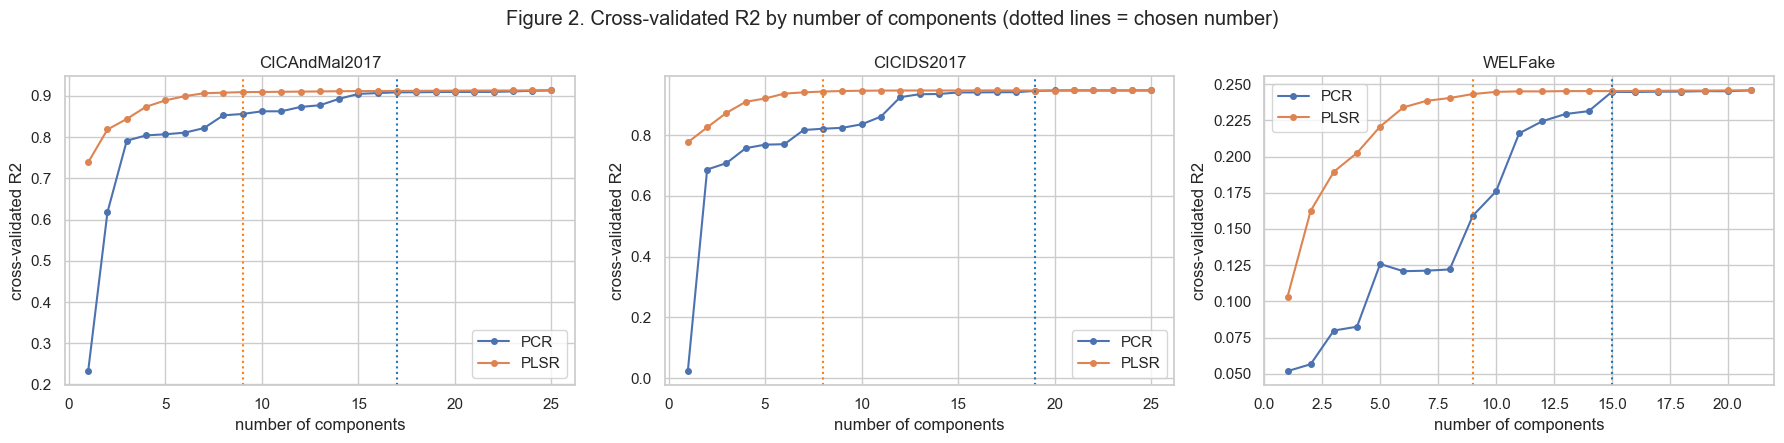

Chosen number of components: {('CICAndMal2017', 'PCR'): 17, ('CICAndMal2017', 'PLSR'): 9, ('CICIDS2017', 'PCR'): 19, ('CICIDS2017', 'PLSR'): 8, ('WELFake', 'PCR'): 15, ('WELFake', 'PLSR'): 9}
CICAndMal2017
             PCR  PLSR
components            
1          0.232 0.739
2          0.618 0.819
3          0.792 0.844
5          0.807 0.889
10         0.863 0.910
25         0.914 0.914 

CICIDS2017
             PCR  PLSR
components            
1          0.023 0.776
2          0.687 0.826
3          0.708 0.873
5          0.769 0.921
10         0.836 0.946
25         0.947 0.947 

WELFake
             PCR  PLSR
components            
1          0.052 0.103
2          0.057 0.163
3          0.080 0.189
5          0.126 0.221
10         0.176 0.245
21         0.246 0.246 



In [82]:
CV = {}
for name, (X_train, X_test, y_train, y_test) in SETS.items():
    idx = np.random.RandomState(SEED).choice(len(X_train), min(50000, len(X_train)), replace=False)
    Xs, ys = X_train.iloc[idx], y_train[idx]
    rows = []
    for k in range(1, X_train.shape[1] + 1):
        pcr = make_pipeline(PCA(n_components=k), LinearRegression())
        pls = PLSRegression(n_components=k, scale=False)
        rows.append({"components": k,
                     "PCR": cross_val_score(pcr, Xs, ys, cv=5, scoring="r2").mean(),
                     "PLSR": cross_val_score(pls, Xs, ys, cv=5, scoring="r2").mean()})
    CV[name] = pd.DataFrame(rows).set_index("components")

def pick_k(curve):
    return int(curve.index[curve >= curve.max() - 0.005].min())

BEST_K = {(name, m): pick_k(CV[name][m]) for name in SETS for m in ["PCR", "PLSR"]}

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, name in zip(axes, SETS):
    CV[name].plot(ax=ax, marker="o", ms=4)
    for m, color in [("PCR", "tab:blue"), ("PLSR", "tab:orange")]:
        ax.axvline(BEST_K[(name, m)], color=color, ls=":")
    ax.set_title(name); ax.set_xlabel("number of components"); ax.set_ylabel("cross-validated R2")
fig.suptitle("Figure 2. Cross-validated R2 by number of components (dotted lines = chosen number)")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig2_components_cv.png", dpi=150); plt.show()

print("Chosen number of components:", BEST_K)
for name in SETS:
    print(name); print(CV[name].iloc[[0, 1, 2, 4, 9, -1]].round(3), "\n")

In [83]:
results = []      # (dataset, model, number of components or features, test R2)
for name, (X_train, X_test, y_train, y_test) in SETS.items():
    results.append((name, "OLS (all columns)", X_train.shape[1], r2_score(y_test, LinearRegression().fit(X_train, y_train).predict(X_test))))
    k = BEST_K[(name, "PCR")]
    pcr = make_pipeline(PCA(n_components=k), LinearRegression()).fit(X_train, y_train)
    results.append((name, "PCR", k, r2_score(y_test, pcr.predict(X_test))))
    k = BEST_K[(name, "PLSR")]
    pls = PLSRegression(n_components=k, scale=False).fit(X_train, y_train)
    results.append((name, "PLSR", k, r2_score(y_test, pls.predict(X_test).ravel())))
pd.DataFrame(results, columns=["dataset", "model", "components", "test R2"])

,dataset,model,components,test R2
0,CICAndMal2017,OLS (all columns),25,0.913
1,CICAndMal2017,PCR,17,0.908
2,CICAndMal2017,PLSR,9,0.908
3,CICIDS2017,OLS (all columns),25,0.948
4,CICIDS2017,PCR,19,0.946
5,CICIDS2017,PLSR,8,0.943
6,WELFake,OLS (all columns),21,0.250
7,WELFake,PCR,15,0.248
8,WELFake,PLSR,9,0.248


Results:
- PLSR needs far fewer components than PCR. With just 1 component, PLSR gets an R2 of 0.74 and 0.78 on the network data, while PCR gets 0.23 and 0.02. PCR's first component is the direction with the most variance in X, but that direction has little to do with throughput. PLSR's first component is chosen because it relates to y.
- With the 0.005 rule, PLSR keeps 8 or 9 components, while PCR needs 15 to 19.
- Test R2 is almost the same as OLS with all 25 columns (for example 0.943 vs 0.948 in CICIDS2017) using a third of the components. So dropping components did not improve accuracy here, because with 240,000 rows there is little overfitting to remove. The benefit is a much smaller model, which is the lesson's explainability point.

## 9. Low variance directions can still matter
The lesson warns that PCR assumes the high variance directions are the useful ones, and fails when a low variance direction is what predicts the target. To check this, I fit a regression on all the components and look at how much each one adds to R2 (because components are uncorrelated, each one's share of R2 is simply its squared correlation with y). I then compare that with how much variance it carries.

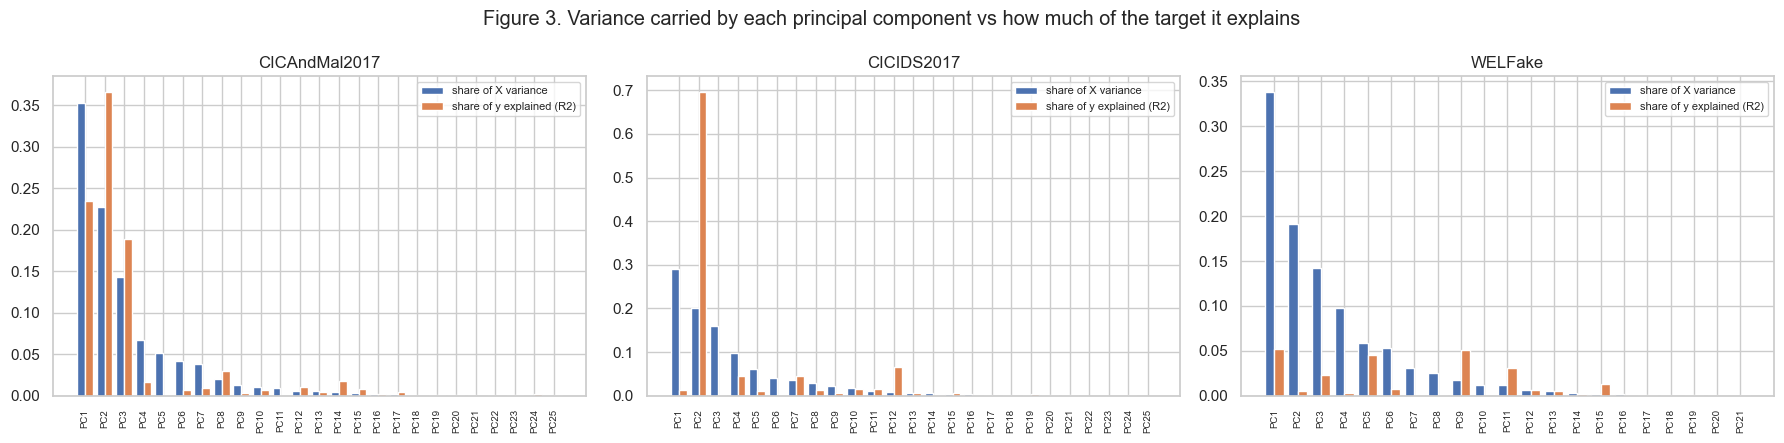

CICAndMal2017 - components that explain the most of y:
     variance share  R2 share
PC2           0.227     0.366
PC1           0.352     0.235
PC3           0.143     0.188 

CICIDS2017 - components that explain the most of y:
      variance share  R2 share
PC2            0.200     0.697
PC12           0.009     0.066
PC7            0.037     0.046 

WELFake - components that explain the most of y:
     variance share  R2 share
PC1           0.339     0.052
PC9           0.017     0.051
PC5           0.059     0.045 



In [86]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
LOWVAR = {}
for ax, (name, (X_train, X_test, y_train, y_test)) in zip(axes, SETS.items()):
    scores = PCAS[name].transform(X_train)
    r2_share = np.array([np.corrcoef(scores[:, j], y_train)[0, 1] ** 2 for j in range(scores.shape[1])])
    var_share = PCAS[name].explained_variance_ratio_
    table = pd.DataFrame({"variance share": var_share, "R2 share": r2_share}, index=[f"PC{j+1}" for j in range(len(var_share))])
    LOWVAR[name] = table
    ax.bar(np.arange(len(table)) - 0.2, table["variance share"], width=0.4, label="share of X variance")
    ax.bar(np.arange(len(table)) + 0.2, table["R2 share"], width=0.4, label="share of y explained (R2)")
    ax.set_xticks(range(len(table))); ax.set_xticklabels(table.index, rotation=90, fontsize=7)
    ax.set_title(name); ax.legend(fontsize=8)
fig.suptitle("Figure 3. Variance carried by each principal component vs how much of the target it explains")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig3_variance_vs_r2.png", dpi=150); plt.show()

for name, table in LOWVAR.items():
    top = table.sort_values("R2 share", ascending=False).head(3)
    print(name, "- components that explain the most of y:"); print(top.round(3), "\n")

This shows the lesson's warning clearly:
- CICIDS2017: PC1 has the most variance (29%) but explains almost none of the target (1%). PC2 explains 70% of the target. PC12 carries less than 1% of the variance but explains 7% of the target, more than any of PC3 to PC11.
- WELFake: PC9 carries under 2% of the variance but explains as much of the target as PC1, which carries 34%.
- CICAndMal2017 is the only dataset where the top variance components are also the most useful ones.

This is why PCR needed so many more components than PLSR in section 8. PCR has to wait for the useful low variance components to come in.

### 9b. Why standardize? (the lesson's miles vs feet point)
Here I run PCR with only the first component on the six original network features before the log transform and without standardizing. Flow duration is measured in microseconds, so its numbers are in the millions, and the first component ends up being almost entirely duration. Then I repeat it with standardized features.

In [89]:
for name in ["CICAndMal2017", "CICIDS2017"]:
    train, test = RAW[name]
    feats = DATA[name][1]
    Xr_train, Xr_test = np.expm1(train[feats]), np.expm1(test[feats])        # back to the original units
    yr_train, yr_test = train["y"], test["y"]
    for label, pipe in [("not standardized", make_pipeline(PCA(n_components=1), LinearRegression())),
                        ("standardized", make_pipeline(StandardScaler(), PCA(n_components=1), LinearRegression()))]:
        pipe.fit(Xr_train, yr_train)
        loadings = pd.Series(pipe.named_steps["pca"].components_[0], index=feats).abs()
        print(f"{name}, {label}: test R2 = {r2_score(yr_test, pipe.predict(Xr_test)):.3f}, "
              f"first component weights: {loadings.round(2).to_dict()}")

CICAndMal2017, not standardized: test R2 = 0.036, first component weights: {'dur': 0.98, 'fwd_pkts': 0.0, 'bwd_pkts': 0.0, 'fwd_len': 0.0, 'bwd_len': 0.0, 'iat': 0.19}
CICAndMal2017, standardized: test R2 = 0.065, first component weights: {'dur': 0.19, 'fwd_pkts': 0.66, 'bwd_pkts': 0.64, 'fwd_len': 0.09, 'bwd_len': 0.34, 'iat': 0.02}
CICIDS2017, not standardized: test R2 = 0.188, first component weights: {'dur': 1.0, 'fwd_pkts': 0.0, 'bwd_pkts': 0.0, 'fwd_len': 0.0, 'bwd_len': 0.0, 'iat': 0.08}
CICIDS2017, standardized: test R2 = 0.001, first component weights: {'dur': 0.07, 'fwd_pkts': 0.7, 'bwd_pkts': 0.7, 'fwd_len': 0.0, 'bwd_len': 0.05, 'iat': 0.04}


Without standardizing, the first component is almost entirely flow duration (weight 0.98 to 1.0). Duration is in microseconds, so its numbers are millions of times bigger than packet counts, and PCA mistakes big units for big importance. That is the lesson's miles vs feet problem. After standardizing, the first component spreads across the features and is mostly the packet counts.

With only one component, standardizing did not give a better R2 in CICIDS2017 (0.001 vs 0.188). The standardized first component is the packet-count direction, which has a lot of variance but little to do with throughput, which is the same point as above. Standardizing makes PCA fair across units, but it does not make the highest variance direction the useful one. That is the job of PLSR.

## 10. Forward and backward selection
Following the lesson, forward selection starts with no features and adds them one at a time, and backward selection starts with all features and removes them one at a time. At each step, the feature added or removed is the one that gives the lowest loss (mean squared error) on a validation set.

The lesson gives two ways to stop: a fixed number of features, or stopping when the validation loss stops getting better. I record the whole path and show both.

For each dataset I split a 20,000 row fitting sample and a separate 20,000 row validation sample out of the training set. The test set is still kept aside for the final score.

In [92]:
from sklearn.metrics import mean_squared_error

def losses(cols, X_fit, y_fit, X_val, y_val):
    # training and validation loss (MSE) of a linear regression on the given columns
    if not cols:
        return mean_squared_error(y_fit, np.full(len(y_fit), y_fit.mean())), mean_squared_error(y_val, np.full(len(y_val), y_fit.mean()))
    model = LinearRegression().fit(X_fit[cols], y_fit)
    return mean_squared_error(y_fit, model.predict(X_fit[cols])), mean_squared_error(y_val, model.predict(X_val[cols]))

def forward_selection(X_fit, y_fit, X_val, y_val, max_features=None):
    chosen, rows, tried = [], [], 0
    remaining = list(X_fit.columns)
    max_features = max_features or len(remaining)
    while remaining and len(chosen) < max_features:
        val_loss = {c: losses(chosen + [c], X_fit, y_fit, X_val, y_val)[1] for c in remaining}
        tried += len(remaining)
        best = min(val_loss, key=val_loss.get)
        chosen.append(best); remaining.remove(best)
        train_l, val_l = losses(chosen, X_fit, y_fit, X_val, y_val)
        rows.append({"features": len(chosen), "added": best, "train loss": train_l, "validation loss": val_l})
    return pd.DataFrame(rows).set_index("features"), tried

def backward_selection(X_fit, y_fit, X_val, y_val):
    chosen, tried = list(X_fit.columns), 0
    train_l, val_l = losses(chosen, X_fit, y_fit, X_val, y_val)
    rows = [{"features": len(chosen), "removed": "(none)", "train loss": train_l, "validation loss": val_l}]
    while len(chosen) > 1:
        val_loss = {c: losses([k for k in chosen if k != c], X_fit, y_fit, X_val, y_val)[1] for c in chosen}
        tried += len(chosen)
        drop = min(val_loss, key=val_loss.get)
        chosen.remove(drop)
        train_l, val_l = losses(chosen, X_fit, y_fit, X_val, y_val)
        rows.append({"features": len(chosen), "removed": drop, "train loss": train_l, "validation loss": val_l})
    return pd.DataFrame(rows).set_index("features"), tried

def stop_point(path, forward=True):
    # forward: stop adding when validation loss stops getting better; backward: stop removing when it stops getting better
    vals = path["validation loss"].values
    sizes = list(path.index)
    for i in range(1, len(vals)):
        if vals[i] >= vals[i - 1]:
            return sizes[i - 1]
    return sizes[-1]

In [93]:
FWD, BWD, SPLIT = {}, {}, {}
for name, (X_train, X_test, y_train, y_test) in SETS.items():
    idx = np.random.RandomState(SEED).permutation(len(X_train))
    fit_i, val_i = idx[:20000], idx[20000:40000]
    X_fit, y_fit, X_val, y_val = X_train.iloc[fit_i], y_train[fit_i], X_train.iloc[val_i], y_train[val_i]
    SPLIT[name] = (X_fit, y_fit, X_val, y_val)
    FWD[name], tried_f = forward_selection(X_fit, y_fit, X_val, y_val)
    BWD[name], tried_b = backward_selection(X_fit, y_fit, X_val, y_val)
    n = X_train.shape[1]
    print(f"{name}: forward stops at {stop_point(FWD[name])} features, backward stops at {stop_point(BWD[name])} features "
          f"(regressions tried: forward {tried_f}, backward {tried_b}; N(N+1)/2 = {n * (n + 1) // 2})")
    print(FWD[name].head(10).round(4).to_string(), "\n")

CICAndMal2017: forward stops at 25 features, backward stops at 25 features (regressions tried: forward 325, backward 324; N(N+1)/2 = 325)
              added  train loss  validation loss
features                                        
1           fwd_len       5.979            5.917
2               iat       3.434            3.418
3          fwd_len2       2.755            2.779
4          bwd_len3       2.445            2.428
5              iat2       2.275            2.260
6              dur2       1.814            1.803
7          fwd_len3       1.715            1.703
8          bwd_len2       1.647            1.641
9         fwd_pkts3       1.611            1.600
10              dur       1.569            1.551 

CICIDS2017: forward stops at 25 features, backward stops at 23 features (regressions tried: forward 325, backward 324; N(N+1)/2 = 325)
                   added  train loss  validation loss
features                                             
1                    iat     

WELFake: forward stops at 20 features, backward stops at 19 features (regressions tried: forward 231, backward 230; N(N+1)/2 = 231)
                      added  train loss  validation loss
features                                                
1             avg_word_len2       0.875            0.924
2             avg_word_len3       0.869            0.867
3               title_words       0.838            0.833
4          title_caps_x_mal       0.822            0.817
5                  exclaim2       0.802            0.802
6                title_caps       0.791            0.794
7              title_chars3       0.780            0.780
8         title_words_x_mal       0.770            0.769
9                 malicious       0.759            0.763
10            exclaim_x_mal       0.758            0.761 



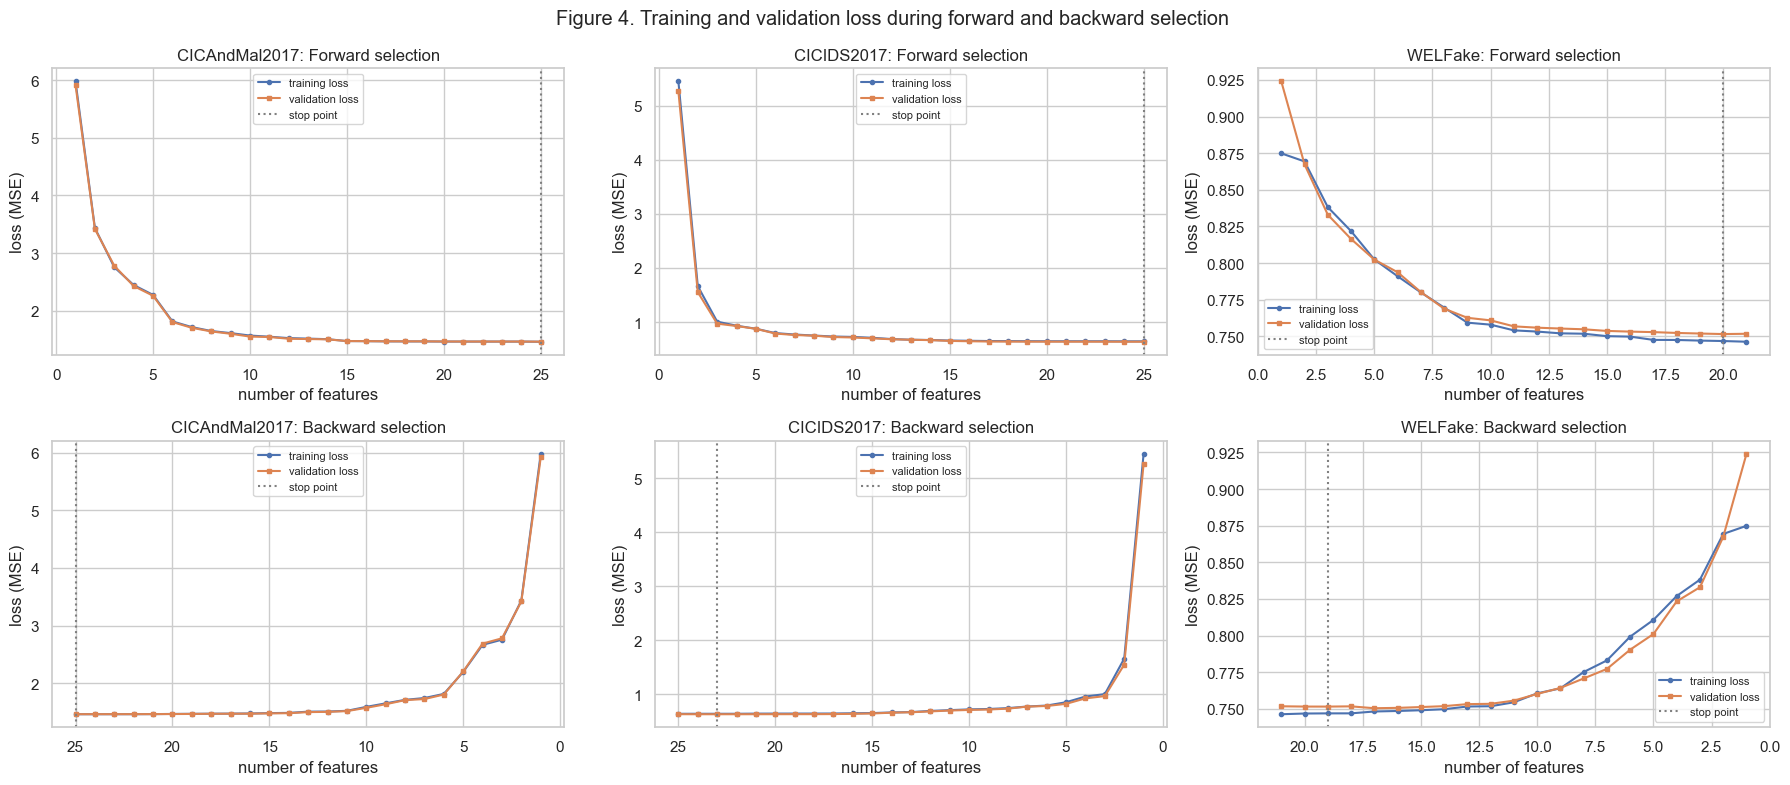

CICAndMal2017 Forward selection: 25 features, test R2 = 0.913
CICAndMal2017 Backward selection: 25 features, test R2 = 0.913
CICAndMal2017 forward selection with a predetermined 5 features ['fwd_len', 'iat', 'fwd_len2', 'bwd_len3', 'iat2']: test R2 = 0.863

CICIDS2017 Forward selection: 25 features, test R2 = 0.948
CICIDS2017 Backward selection: 23 features, test R2 = 0.948
CICIDS2017 forward selection with a predetermined 5 features ['iat', 'bwd_len', 'fwd_len3', 'fwd_len2', 'fwd_pkts_x_mal']: test R2 = 0.930

WELFake Forward selection: 20 features, test R2 = 0.250
WELFake Backward selection: 19 features, test R2 = 0.250
WELFake forward selection with a predetermined 5 features ['avg_word_len2', 'avg_word_len3', 'title_words', 'title_caps_x_mal', 'exclaim2']: test R2 = 0.201



CICIDS2017 Backward selection: 23 features, test R2 = 0.948
CICIDS2017 forward selection with a predetermined 5 features ['iat', 'bwd_len', 'fwd_len3', 'fwd_len2', 'fwd_pkts_x_mal']: test R2 = 0.930

WELFake Forward selection: 20 features, test R2 = 0.250
WELFake Backward selection: 19 features, test R2 = 0.250
WELFake forward selection with a predetermined 5 features ['avg_word_len2', 'avg_word_len3', 'title_words', 'title_caps_x_mal', 'exclaim2']: test R2 = 0.201



In [94]:
fig, axes = plt.subplots(2, 3, figsize=(18, 8))
for i, name in enumerate(SETS):
    for row, (path, label) in enumerate([(FWD[name], "Forward"), (BWD[name], "Backward")]):
        ax = axes[row, i]
        ax.plot(path.index, path["train loss"], "o-", ms=3, label="training loss")
        ax.plot(path.index, path["validation loss"], "s-", ms=3, label="validation loss")
        ax.axvline(stop_point(path), color="gray", ls=":", label="stop point")
        ax.set_title(f"{name}: {label} selection"); ax.set_xlabel("number of features"); ax.set_ylabel("loss (MSE)")
        if row == 1: ax.invert_xaxis()      # backward selection moves from right to left
        ax.legend(fontsize=8)
fig.suptitle("Figure 4. Training and validation loss during forward and backward selection")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig4_selection.png", dpi=150); plt.show()

for name, (X_train, X_test, y_train, y_test) in SETS.items():
    for label, path, key in [("Forward selection", FWD[name], "added"), ("Backward selection", BWD[name], "removed")]:
        k = stop_point(path)
        if key == "added":
            cols = list(path["added"].iloc[:k])
        else:
            removed = list(path["removed"].iloc[1:].loc[path.index[1:] >= k])
            cols = [c for c in X_train.columns if c not in removed]
        test_r2 = r2_score(y_test, LinearRegression().fit(X_train[cols], y_train).predict(X_test[cols]))
        results.append((name, label, k, test_r2))
        print(f"{name} {label}: {k} features, test R2 = {test_r2:.3f}")
    cols5 = list(FWD[name]["added"].iloc[:5])        # the other stopping rule: a predetermined 5 features
    test_r2 = r2_score(y_test, LinearRegression().fit(X_train[cols5], y_train).predict(X_test[cols5]))
    results.append((name, "Forward selection (5 features)", 5, test_r2))
    print(f"{name} forward selection with a predetermined 5 features {cols5}: test R2 = {test_r2:.3f}\n")

Results:
- The first features picked are the same main drivers found in Weeks 1 and 2: forward packet length and inter-arrival time for CICAndMal2017, inter-arrival time and backward packet length for CICIDS2017, and word length, title length and title capitals for WELFake.
- Figure 4 shows the lesson's pattern. In forward selection both losses fall quickly for the first 3 to 6 features, then flatten. In backward selection the training loss only goes up as features are removed, and the validation loss barely moves until only a few features are left.
- Stopping rule 1, stop when validation loss stops getting better: this keeps almost everything (25, 25 and 20 features forward; 25, 23 and 19 backward). With 20,000 rows each extra feature still helps a tiny amount, so the strict rule rarely stops early. Test R2 is the same as OLS.
- Stopping rule 2, a predetermined 5 features: test R2 of 0.863, 0.930 and 0.201. That is most of the accuracy with a fifth of the features, which is much easier to explain to an analyst.
- Interaction terms with the malicious label get picked early in CICIDS2017 (5th, forward packets times malicious) and WELFake (4th, title capitals times fake), but not in CICAndMal2017. This matches Week 1: malicious traffic changes the slopes in CICIDS2017 and fake news changes them in WELFake, but malware barely changes them in CICAndMal2017.
- Both methods tried exactly N(N+1)/2 regressions (325 for 25 features), as the lesson says, out of over 33 million possible sets.

### 10b. Limitations: forward selection does not try every combination
The lesson says forward and backward selection only reach about N(N+1)/2 of the 2^N - 1 possible feature sets. With only the original base features (6 for the network data, 5 for WELFake), it is possible to try every combination and check whether forward selection still finds the best set of each size.

In [97]:
from itertools import combinations

for n in [3, 4, 10, 25]:
    print(f"{n} features: {2 ** n - 1:,} possible combinations, forward selection tries at most {n * (n + 1) // 2}")
print()

BASE = {"CICAndMal2017": NET_FEATS, "CICIDS2017": NET_FEATS, "WELFake": WEL_FEATS}
for name, base in BASE.items():
    X_fit, y_fit, X_val, y_val = SPLIT[name]
    Xf, Xv = X_fit[base], X_val[base]
    best_all = {}
    for k in range(1, len(base) + 1):
        scores = {combo: losses(list(combo), Xf, y_fit, Xv, y_val)[1] for combo in combinations(base, k)}
        best_all[k] = min(scores, key=scores.get)
    fwd, _ = forward_selection(Xf, y_fit, Xv, y_val)
    print(name)
    for k in range(1, len(base) + 1):
        fwd_set = tuple(fwd["added"].iloc[:k])
        same = set(fwd_set) == set(best_all[k])
        print(f"  {k} features: forward = {sorted(fwd_set)}, best of all = {sorted(best_all[k])}, same: {same}")

3 features: 7 possible combinations, forward selection tries at most 6
4 features: 15 possible combinations, forward selection tries at most 10
10 features: 1,023 possible combinations, forward selection tries at most 55
25 features: 33,554,431 possible combinations, forward selection tries at most 325

CICAndMal2017
  1 features: forward = ['fwd_len'], best of all = ['fwd_len'], same: True
  2 features: forward = ['fwd_len', 'iat'], best of all = ['fwd_len', 'iat'], same: True
  3 features: forward = ['bwd_len', 'fwd_len', 'iat'], best of all = ['bwd_len', 'fwd_len', 'iat'], same: True
  4 features: forward = ['bwd_len', 'dur', 'fwd_len', 'iat'], best of all = ['bwd_len', 'dur', 'fwd_len', 'fwd_pkts'], same: False
  5 features: forward = ['bwd_len', 'dur', 'fwd_len', 'fwd_pkts', 'iat'], best of all = ['bwd_len', 'dur', 'fwd_len', 'fwd_pkts', 'iat'], same: True
  6 features: forward = ['bwd_len', 'bwd_pkts', 'dur', 'fwd_len', 'fwd_pkts', 'iat'], best of all = ['bwd_len', 'bwd_pkts', 'd

CICIDS2017
  1 features: forward = ['iat'], best of all = ['iat'], same: True
  2 features: forward = ['bwd_len', 'iat'], best of all = ['bwd_len', 'iat'], same: True
  3 features: forward = ['bwd_len', 'fwd_len', 'iat'], best of all = ['bwd_len', 'fwd_len', 'iat'], same: True
  4 features: forward = ['bwd_len', 'bwd_pkts', 'fwd_len', 'iat'], best of all = ['bwd_len', 'bwd_pkts', 'fwd_len', 'iat'], same: True
  5 features: forward = ['bwd_len', 'bwd_pkts', 'dur', 'fwd_len', 'iat'], best of all = ['bwd_len', 'bwd_pkts', 'dur', 'fwd_len', 'iat'], same: True
  6 features: forward = ['bwd_len', 'bwd_pkts', 'dur', 'fwd_len', 'fwd_pkts', 'iat'], best of all = ['bwd_len', 'bwd_pkts', 'dur', 'fwd_len', 'fwd_pkts', 'iat'], same: True


WELFake
  1 features: forward = ['title_words'], best of all = ['title_words'], same: True
  2 features: forward = ['title_caps', 'title_words'], best of all = ['title_caps', 'title_words'], same: True
  3 features: forward = ['avg_word_len', 'title_caps', 'title_words'], best of all = ['avg_word_len', 'title_caps', 'title_words'], same: True
  4 features: forward = ['avg_word_len', 'exclaim', 'title_caps', 'title_words'], best of all = ['avg_word_len', 'exclaim', 'title_caps', 'title_words'], same: True
  5 features: forward = ['avg_word_len', 'exclaim', 'title_caps', 'title_chars', 'title_words'], best of all = ['avg_word_len', 'exclaim', 'title_caps', 'title_chars', 'title_words'], same: True


Even though forward selection only checks a small part of all possible sets, on the base features it found the best set of every size in 16 of 17 cases. The one miss was CICAndMal2017 with 4 features: forward selection had already locked in inter-arrival time, so it never tried the best 4-feature set, which uses forward packets instead. This is the lesson's (B, C) example on real data: once a feature is chosen, every later set has to include it. With 25 columns the gap is far bigger (325 sets tried out of 33,554,431), so there is no guarantee the selected set is the best one.

### 10c. Why the p-values cannot be trusted
The lesson warns that after trying many regressions, some will look significant by chance. To show this, I make 25 columns of pure random noise and a random target, so nothing is real. I run forward selection to pick 3 columns using 200 rows, then fit sm.OLS on those 200 rows and look at the usual p-values. This is repeated 200 times. I do it two ways: picking each feature by its loss on the same 200 rows (the usual way), and picking by the loss on a separate validation set (the way used in section 10).

In [100]:
rng = np.random.RandomState(SEED)
count = {"picked by training loss": 0, "picked by validation loss": 0}
for rep in range(200):
    noise = pd.DataFrame(rng.normal(size=(400, 25)), columns=[f"noise{j}" for j in range(25)])
    target = rng.normal(size=400)
    X_fit, y_fit = noise.iloc[:200], target[:200]
    # usual way: pick features by the loss on the same 200 rows used for the p-values
    picked_train = []
    for step in range(3):
        train_loss = {c: losses(picked_train + [c], X_fit, y_fit, X_fit, y_fit)[0] for c in noise.columns if c not in picked_train}
        picked_train.append(min(train_loss, key=train_loss.get))
    # my way above: pick features by the loss on a separate validation set
    picked_val = list(forward_selection(X_fit, y_fit, noise.iloc[200:], target[200:], max_features=3)[0]["added"])
    for label, picked in [("picked by training loss", picked_train), ("picked by validation loss", picked_val)]:
        p_values = sm.OLS(y_fit, sm.add_constant(X_fit[picked])).fit().pvalues.drop("const")
        count[label] += (p_values < 0.05).any()
for label, c in count.items():
    print(f"Features {label}: in {c} of 200 runs ({c / 200:.0%}) at least one pure-noise feature had p < 0.05.")
print("If the p-values were honest, this would happen in about 14% of runs (1 - 0.95^3).")

Features picked by training loss: in 161 of 200 runs (80%) at least one pure-noise feature had p < 0.05.
Features picked by validation loss: in 28 of 200 runs (14%) at least one pure-noise feature had p < 0.05.
If the p-values were honest, this would happen in about 14% of runs (1 - 0.95^3).


This shows the lesson's warning clearly. When the features are picked by their loss on the same rows, at least one pure-noise feature looks significant (p < 0.05) in 80% of runs, even though nothing is real. If the p-values were honest, that would happen in only about 14% of runs. When the features are picked using a separate validation set, the rate drops back to 14%. So p-values from a stepwise model should not be trusted unless the selection and the testing use different data. That is one more reason this notebook judges models by validation and test results instead of p-values.

## 11. Summary and cross-domain comparison

,dataset,model,components or columns,test R2
0,CICAndMal2017,OLS (all columns),25,0.913
1,CICAndMal2017,PCR,17,0.908
2,CICAndMal2017,PLSR,9,0.908
3,CICIDS2017,OLS (all columns),25,0.948
4,CICIDS2017,PCR,19,0.946
5,CICIDS2017,PLSR,8,0.943
6,WELFake,OLS (all columns),21,0.250
7,WELFake,PCR,15,0.248
8,WELFake,PLSR,9,0.248
9,CICAndMal2017,Forward selection,25,0.913


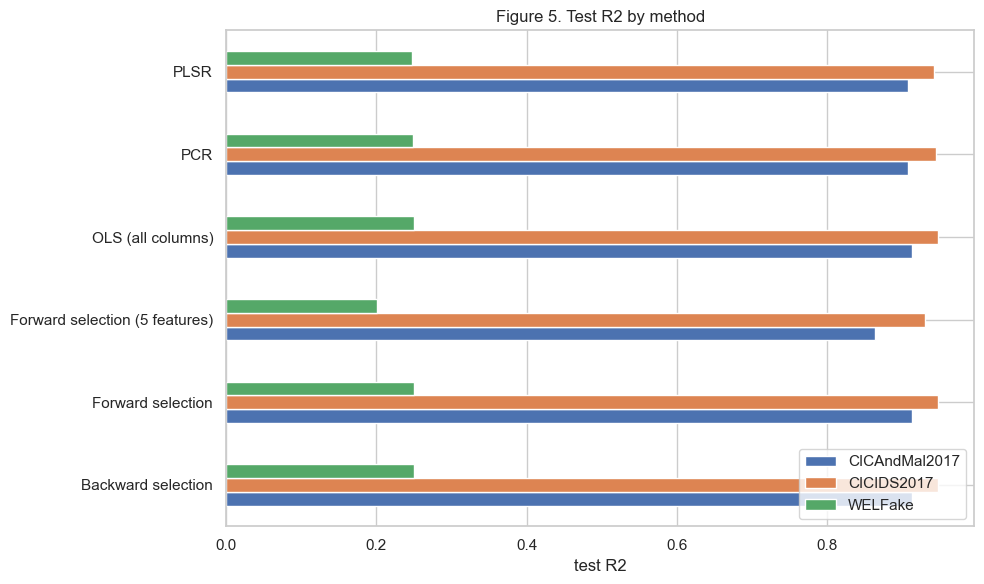

In [103]:
summary = pd.DataFrame(results, columns=["dataset", "model", "components or columns", "test R2"])
display(summary)

pivot = summary.pivot(index="model", columns="dataset", values="test R2")
pivot.plot.barh(figsize=(10, 6), title="Figure 5. Test R2 by method")
plt.xlabel("test R2"); plt.ylabel(""); plt.legend(loc="lower right"); plt.tight_layout(); plt.savefig(FIG_DIR / "fig5_summary.png", dpi=150); plt.show()

The first PLS component is the single direction in the data that is most related to the target. Comparing its weights in the two network datasets shows whether both domains rely on the same mix of features.

Correlation between the two domains' first PLS component weights: 0.842


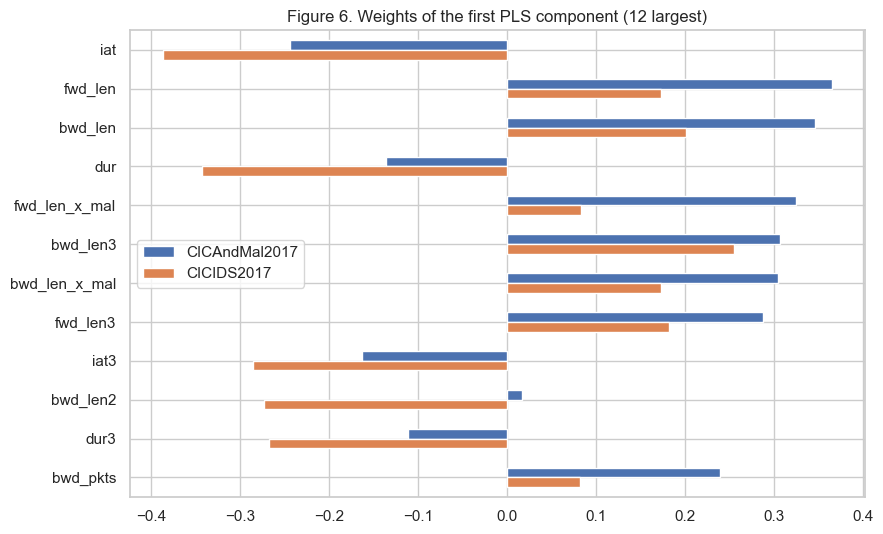

,CICAndMal2017,CICIDS2017
iat,-0.244,-0.387
fwd_len,0.364,0.173
bwd_len,0.346,0.201
dur,-0.136,-0.343
fwd_len_x_mal,0.324,0.083
bwd_len3,0.307,0.255
bwd_len_x_mal,0.304,0.173
fwd_len3,0.287,0.182
iat3,-0.163,-0.286
bwd_len2,0.016,-0.273


In [105]:
weights = {}
for name in ["CICAndMal2017", "CICIDS2017"]:
    X_train, X_test, y_train, y_test = SETS[name]
    pls1 = PLSRegression(n_components=1, scale=False).fit(X_train, y_train)
    # flip the sign so that a higher component score means a higher target in both datasets
    weights[name] = pd.Series(pls1.x_weights_[:, 0] * np.sign(pls1.y_loadings_[0, 0]), index=X_train.columns)
weights = pd.DataFrame(weights)
print("Correlation between the two domains' first PLS component weights:", round(weights.corr().iloc[0, 1], 3))

top = weights.abs().max(axis=1).sort_values(ascending=False).index[:12]
weights.loc[top].plot.barh(figsize=(9, 5.5), title="Figure 6. Weights of the first PLS component (12 largest)")
plt.gca().invert_yaxis(); plt.tight_layout(); plt.savefig(FIG_DIR / "fig6_pls_weights.png", dpi=150); plt.show()
weights.loc[top].round(3)

The first PLS component of the two network datasets is very similar (correlation 0.84 between the weights). In both, throughput goes up with packet length and down with inter-arrival time and duration. So the main structure of network traffic is shared across the two domains.

The weights on the malicious interaction columns differ more (for example 0.32 vs 0.08 for packet length times malicious). Part of this is because 80% of the CICAndMal2017 sample is malware, so the interaction column is close to a copy of the feature itself. Together with Weeks 1 and 2, this points to a shared baseline of how traffic behaves, with the malicious part on top being domain-specific.

For Module C, PLSR, forward selection and lasso all agree on a short list of main features. That is a good shared feature set for the SHAP comparison.

## 12. Think About It

A low variance feature or component can still be important when small changes in it cause large changes in the target. My data has examples:
- In CICIDS2017, PC12 carries less than 1% of the variance in X but explains more of the target than nine higher-variance components.
- Without standardizing, a feature measured in small units (like packet counts in the tens) has tiny variance next to flow duration in microseconds, even though packet size and count drive throughput. PCA would rank it near the bottom only because of its units.
- A security example: a flag like a rare TCP flag or the malicious label itself may almost always be 0, so its variance is tiny, but when it is 1 it can change the outcome a lot.

This is the reason to prefer PLSR (or to check each component's relationship with y) instead of trusting the variance alone.

Second Think About It (forward selection with A, B, C, D added in the order A, B, C, D):
- Level 1 tries A, B, C and D alone and keeps A.
- Level 2 tries (A, B), (A, C), (A, D) and keeps (A, B).
- Level 3 tries (A, B, C), (A, B, D) and keeps (A, B, C).
- Level 4 tries (A, B, C, D).

That is 10 of the 15 possible combinations, which matches 4 x 5 / 2 = 10. The ones never tried are (B, C), (B, D), (C, D), (A, C, D) and (B, C, D). Every one of them is either missing A or missing B, which forward selection locked in early.

## 13. Notes for the Milestone One write-up
| Rubric item | What I did |
|---|---|
| Avoiding overfitting | Fewer components or features instead of all of them, 80/20 train/test split, 5-fold cross-validation for the number of components, a separate validation set for forward and backward selection |
| Metrics | Test R2, cross-validated R2, validation loss (MSE), share of variance explained |
| Hyperparameter tuning | Number of components (PCR and PLSR) chosen as the smallest number within 0.005 of the best cross-validated R2; number of features (forward and backward selection) chosen where the validation loss stops getting better |
| How EDA helped | The Week 1 VIF results and the Module B PCA showed the features were highly collinear, which is the situation PCR and PLSR are made for |